# 5-13 특허 가져오기 — 키워드·회사별 특허와 상장사 출원인

**질문 예시:** "작년 배터리 특허 출원한 상장사 순위 줘", "LG에너지솔루션 특허 월별 추이 보여줘"

DeepSearch `["patent"]`에는 특허정보원(KIPRIS)의 국내 특허·실용신안이 들어 있습니다.
문서마다 `patent` 항목에 출원·등록 번호와 날짜, 등록 상태, IPC 분류, 청구항, **출원인(법인번호·사업자번호 포함)**, 발명자, 인용 특허가 있습니다.
출원인 이름은 공식명('주식회사 엘지에너지솔루션')이라, 상장사와 맞출 때는 **법인번호·사업자번호**를 씁니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/5_data_lookup/13_patent.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"
KEYWORD = "배터리"
YEAR_FROM, YEAR_TO = "2025-01-01", "2025-12-31"   # 특허는 공개까지 시차가 있어 작년 기준이 안정적
COMPANY = "엘지에너지솔루션"                        # 특허의 회사 이름은 공식명

## 1. 상장사 식별번호 지도
상장사(보통주)의 법인번호·사업자번호 → 종목코드. (식별번호는 보통주·우선주가 같아 보통주만 씁니다)

In [4]:
sym = ds_df("GetStockSymbols()")
L = sym[sym.company_type_l1.isin(["1", "2"]) & sym.symbol.str.endswith("0")].copy()
L["code"] = L.symbol.str.replace("KRX:", "", regex=False)
BY_CRID = dict(zip(L.company_rid.dropna().str.replace("-", ""), L.code))
BY_BRID = dict(zip(L.business_rid.dropna().str.replace("-", ""), L.code))
NAME = dict(zip(L.code, L.entity_name)); MKT = dict(zip(L.code, L.market))
print(f"상장사 {len(L):,}개 (법인번호 {len(BY_CRID):,} · 사업자번호 {len(BY_BRID):,})")

상장사 2,770개 (법인번호 2,748 · 사업자번호 2,749)


## 2. 키워드 특허 받기 — '배터리', 2025년
문서 원본(`patent` 항목 포함)이 필요해 `ds()`로 직접 받습니다. 한 페이지 100건, 여기서는 5페이지(500건)까지.

In [5]:
def patent_docs(query, date_from, date_to, pages=5):
    docs, total = [], 0
    for p in range(1, pages + 1):
        c = ds(f'DocumentSearch(["patent"],[],{json.dumps(query, ensure_ascii=False)},count=100,page={p},'
               f'date_from={date_from},date_to={date_to})')["data"]["pods"][1]["content"]
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        batch = d.get("docs") or []
        docs += batch
        if not batch or p * 100 >= total:   # 페이지가 100건보다 짧게 와도 뒤에 더 있을 수 있음
            break
    print(f"특허 '{query}' {date_from}~{date_to}: 전체 {total:,}건 중 {len(docs)}건")
    return docs

def flatten(docs):
    rows = []
    for x in docs:
        p = x.get("patent") or {}
        apps = p.get("applicants") or []
        codes = []
        for a in apps:
            c = BY_CRID.get(str(a.get("company_rid") or "").replace("-", "")) or \
                BY_BRID.get(str(a.get("business_rid") or "").replace("-", ""))
            if c:
                codes.append(c)
        ipc = p.get("ipc_codes") or []
        rows.append({
            "출원일": (p.get("application") or {}).get("date"),
            "출원번호": (p.get("application") or {}).get("uid"),
            "제목": x.get("title"),
            "출원인": ", ".join(a.get("name_ko", "") for a in apps),
            "상장사": ", ".join(NAME[c] for c in dict.fromkeys(codes)),
            "_codes": list(dict.fromkeys(codes)),
            "상태": p.get("registration_status"),
            "IPC": (ipc[0].get("subclass") or {}).get("code") if ipc else None,
            "url": x.get("content_url"),
        })
    return pd.DataFrame(rows)

raw = patent_docs(KEYWORD, YEAR_FROM, YEAR_TO)
pt = flatten(raw)
print(f"받은 {len(pt)}건 중 상장사 출원 {int((pt._codes.str.len() > 0).sum())}건")
pt[["출원일", "제목", "출원인", "상장사", "상태", "IPC"]].head(8)

특허 '배터리' 2025-01-01~2025-12-31: 전체 3,458건 중 500건
받은 500건 중 상장사 출원 169건


,출원일,제목,출원인,상장사,상태,IPC
0,2025-12-31,자동 액침이 가능한 모듈형 배터리 보관함,주식회사 한국방염기술,,등록,A62C
1,2025-12-31,이기종 센서 일체형 주차면 카메라 환경에서 멀티모달 AI 기반 전기차 화재 감지 시스템,주식회사 넥스파시스템,,등록,G08B
2,2025-12-31,"에너지 소비량, 계시별 요금제, 및 배터리 열화를 고려한 BLP기반 전기버스 충전 일정 최적화방법, ...",가천대학교 산학협력단,,등록,G06Q
3,2025-12-31,전기차 화재 및 전기 화재용 소화약제 및 이의 제조방법,"주식회사 에이바이오텍, 주식회사 인벤트파트너스",,등록,A62D
4,2025-12-31,배터리 팩 및 이를 포함하는 자동차,주식회사 엘지에너지솔루션,LG에너지솔루션,공개,H01M
5,2025-12-31,태양광 에너지원을 이용한 고효율 AI CCTV 탑재 가로등 시스템 및 이의 제어 방법,수엔지니어링 주식회사,,등록,F21V
6,2025-12-30,"실리콘-탄소 입자, 음극 극판 및 배터리",,,공개,H01M
7,2025-12-30,자가발전 및 태양광 전력을 이용한 정전기 집진식 공기정화 기둥을 구비한 실외 운동 시설물,,,등록,E04H


## 3. 상장사 출원인 순위와 등록 상태·IPC 분류

In [6]:
rank = pt.explode("_codes").dropna(subset=["_codes"]).groupby("_codes").size().sort_values(ascending=False)
rank = pd.DataFrame({"상장사": [NAME[c] for c in rank.index], "시장": [MKT[c] for c in rank.index], "특허 수": rank.values})
print("등록 상태:", pt.상태.value_counts().to_dict())
print("IPC 상위:", pt.IPC.value_counts().head(6).to_dict(), "(H01M = 전지)")
rank.head(12)

등록 상태: {'공개': 274, '등록': 219, '거절': 6, '취하': 1}
IPC 상위: {'H01M': 185, 'G01R': 58, 'B60L': 38, 'H02J': 24, 'G06Q': 16, 'A62C': 13} (H01M = 전지)


,상장사,시장,특허 수
0,LG에너지솔루션,KOSPI,107
1,한국전력,KOSPI,10
2,현대차,KOSPI,8
3,기아,KOSPI,8
4,LG화학,KOSPI,7
5,LX하우시스,KOSPI,3
6,아하,KONEX,3
7,LG이노텍,KOSPI,3
8,나노팀,KOSDAQ,3
9,삼성SDI,KOSPI,3


## 4. 회사별 — 엘지에너지솔루션 특허 월별 추이
특허의 `securities.name`에는 공식명이 들어 있어 그대로 지정합니다. 건수 추이는 `DocumentTrends`로 받습니다.

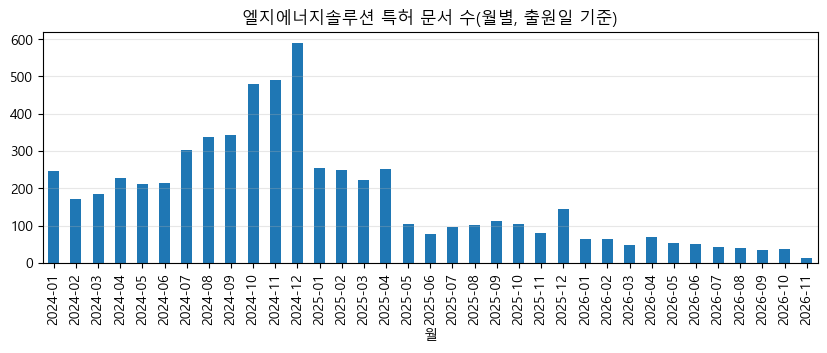

최근 6개월: [['2026-06', 50], ['2026-07', 42], ['2026-08', 39], ['2026-09', 35], ['2026-10', 37], ['2026-11', 14]] ← 공개 시차로 최근이 적게 보입니다


In [7]:
tr = doc_trends("patent", [], f"securities.name:{COMPANY}", "2024-01-01", ASOF, interval="1M")
tr["월"] = tr.date.dt.strftime("%Y-%m")
ax = tr.plot.bar(x="월", y="count", figsize=(10, 3), legend=False, title=f"{COMPANY} 특허 문서 수(월별, 출원일 기준)")
ax.grid(alpha=.3, axis="y"); plt.show()
print("최근 6개월:", tr.tail(6)[["월", "count"]].values.tolist(), "← 공개 시차로 최근이 적게 보입니다")

## 결과 읽는 법과 한계
- **공개 시차:** 특허는 출원 후 보통 18개월 뒤 공개되므로 최근 1년 출원은 일부만 보입니다. 추이는 2년 전까지가 믿을 만합니다.
- **출원인 매칭:** 법인번호·사업자번호가 있는 출원인만 상장사로 맞출 수 있습니다. 대학·연구소·개인 출원은 빠집니다.
- 날짜(`created_at`)는 출원일입니다. 등록 여부는 `patent.registration_status`로 봅니다.